In [ ]:
!pip install pyDOE

  Preparing metadata (setup.py) ... done
  Created wheel for pyDOE: filename=pyDOE-0.3.8-py3-none-any.whl size=18171 sha256=6440af457bca0b6df9c9f1cc5aadc5c367b67a3ba1438246e32d2dc437f97021
  Stored in directory: /root/.cache/pip/wheels/ce/b6/d7/c6b64746dba6433c593e471e0ac3acf4f36040456d1d160d17
Successfully built pyDOE


In [ ]:
import jax
import jax.numpy as jnp
from flax import linen as nn
import optax
import copy

from typing import Callable

from functools import partial

import tensorflow as tf
from pyDOE import lhs
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp
from scipy.optimize import fsolve

from jax import config
config.update("jax_enable_x64", True)

In [ ]:
# Boundaries of the computational domain
t0, tfinal = 0.0, 0.25

In [ ]:
# Number of particles to consider
particles = 5

In [ ]:
# Define the normalization layer
class Normalize(nn.Module):
  xmin: float
  xmax: float

  @nn.compact
  def __call__(self, x):
    return 2.0*(x-self.xmin)/(self.xmax - self.xmin) - 1.0

In [ ]:
class HardConstraint(nn.Module):
  t0: float
  tfinal: float
  u0: float

  @nn.compact
  def __call__(self, inputs):
    t, nn = inputs
    return self.u0 + (t-self.t0)/(self.tfinal-self.t0)*nn

In [ ]:
class CombineBranches(nn.Module):
  @nn.compact
  def __call__(self, inp1, inp2):
    mult = jnp.sum(inp1*inp2, axis=1)
    # For consistency, we add the batch dimension back here
    out = jnp.reshape(mult, (-1,1))
    return out

In [ ]:
class MLP(nn.Module):

  layers: int
  units: int
  particles: int

  @nn.compact
  def __call__(self, inp):
    b = inp
    for i in range(self.layers-1):
      b = nn.Dense(self.units)(b)
      b = nn.tanh(b)
    out = nn.Dense(self.particles*self.units,
                   kernel_init=nn.initializers.normal(1e-3),
                   bias_init=nn.initializers.zeros)(b)
    return out

In [ ]:
class DeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int
  particles: int

  @nn.compact
  def __call__(self, t, u):

    # # Add the batch dimension
    if u.ndim == 1:
      u = jnp.reshape(u, (1,-1))

    # Add the batch dimension
    t = jnp.reshape(t, (-1,1))

    b = Normalize(self.t0, self.tfinal)(t)

    trunk_net_q = MLP(self.layers, self.units, self.particles)(b)
    branch_net_q = MLP(self.layers, self.units, self.particles)(u)

    trunk_net_p = MLP(self.layers, self.units, self.particles)(b)
    branch_net_p = MLP(self.layers, self.units, self.particles)(u)

    outq, outp = [], []

    # Split into trunk/branch for q and p
    for i in range(self.particles):
      trunk_q = trunk_net_q[:,i*self.units:(i+1)*self.units]
      branch_q = branch_net_q[:,i*self.units:(i+1)*self.units]
      combined_q = CombineBranches()(trunk_q, branch_q)
      constrained_q = HardConstraint(self.t0, self.tfinal, u[:,i:i+1])([t, combined_q])

      trunk_p = trunk_net_p[:,i*self.units:(i+1)*self.units]
      branch_p = branch_net_p[:,i*self.units:(i+1)*self.units]
      combined_p = CombineBranches()(trunk_p, branch_p)
      constrained_p = HardConstraint(self.t0, self.tfinal,
                                     u[:,self.particles+i:self.particles+i+1])([t, combined_p])

      outq.append(jnp.reshape(constrained_q, (-1,)))
      outp.append(jnp.reshape(constrained_p, (-1,)))

    outq = jnp.array(outq)
    outp = jnp.array(outp)

    return outq, outp

In [ ]:
# Create the model
deeponet = DeepONet(t0, tfinal, layers=6, units=40, particles=particles)

# Initialize the model parameters
params = deeponet.init(jax.random.PRNGKey(0), jnp.ones((10,)), jnp.ones((10,2*particles)))

In [ ]:
# Define the collocation points over the domain [t_0, t_1]
def defineCollocationPoints(t_bdry, N=100):

    # Sample points where to evaluate the PDE
  ode_points = t_bdry[0] + (t_bdry[1] - t_bdry[0])*lhs(1, N)

  qs = np.random.uniform(-0.5, 0.5, size=(N, particles))
  ps = np.random.uniform(-0.5, 0.5, size=(N, particles))

  zsensors = np.column_stack((qs, ps))

  return (ode_points, zsensors)

In [ ]:
# Define the collocation points
(de_points, zsensors) = defineCollocationPoints([t0, tfinal], 10000)

In [ ]:
@jax.jit
def train_step(params, pdes, z):
  t = pdes[:,0]

  # Helper functions
  def a_model(t, z, component, params):
    return deeponet.apply(params, t, z)[0][component][0]
  def b_model(t, z, component, params):
    return deeponet.apply(params, t, z)[1][component][0]
  def a(t, z, component, params):
    return jax.vmap(a_model, [0, 0, None, None])(t, z, component, params)
  def b(t, z, component, params):
    return jax.vmap(b_model, [0, 0, None, None])(t, z, component, params)
  def a_t(t, z, component, params):
    return jax.vmap(jax.grad(a_model, 0), [0, 0, None, None])(t, z, component, params)
  def b_t(t, z, component, params):
    return jax.vmap(jax.grad(b_model, 0), [0, 0, None, None])(t, z, component, params)

  # Soft-constrained DeepONet loss
  def loss(params, t, z):
    eqna, eqnb = [], []
    for k in range(particles):
      if k == 0:
        eqna.append(a_t(t, z, k, params) - 2*(b(t, z, k, params)**2 - b(t, z, particles-1, params)**2))
        eqnb.append(b_t(t, z, k, params) - b(t, z, k, params)*(a(t, z, k+1, params)-a(t, z, k, params)))
      elif k == particles-1:
        eqna.append(a_t(t, z, k, params) - 2*(b(t, z, k, params)**2 - b(t, z, k-1, params)**2))
        eqnb.append(b_t(t, z, k, params) - b(t, z, k, params)*(a(t, z, 0, params)-a(t, z, k, params)))
      else:
        eqna.append(a_t(t, z, k, params) - 2*(b(t, z, k, params)**2 - b(t, z, k-1, params)**2))
        eqnb.append(b_t(t, z, k, params) - b(t, z, k, params)*(a(t, z, k+1, params)-a(t, z, k, params)))

    eqna = jnp.array(eqna)
    eqnb = jnp.array(eqnb)

    return jnp.mean(jnp.sum(eqna**2) + jnp.sum(eqnb**2))

  return jax.value_and_grad(loss)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [ ]:
def train_network(params, des, zsensor, epochs=100):

  # Number of ICs and total number of DE collocation points
  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  lr = 1e-3
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensors)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.zeros(epochs)

  for i in range(epochs):

    for (des_batch, z_batch) in ds:

      loss, grads = train_step(params, des_batch.numpy(), z_batch.numpy())
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 100 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [ ]:
epochs = 10000
params, loss = train_network(params, de_points, zsensors, epochs)

Loss in epoch 0: 2.8925773034885642
Loss in epoch 100: 0.07565322488011497
Loss in epoch 200: 0.049368375401815046
Loss in epoch 300: 0.04066000821275658
Loss in epoch 400: 0.031139829294854388
Loss in epoch 500: 0.03136841096383623
Loss in epoch 600: 0.024208721731203198
Loss in epoch 700: 0.02810602946588962
Loss in epoch 800: 0.018691936937622236
Loss in epoch 900: 0.021916009002927617
Loss in epoch 1000: 0.017148227275362516
Loss in epoch 1100: 0.017466875110036115
Loss in epoch 1200: 0.015280656356819688
Loss in epoch 1300: 0.014801065427316544
Loss in epoch 1400: 0.012019513614736374
Loss in epoch 1500: 0.01122574296418623
Loss in epoch 1600: 0.0104962326097054
Loss in epoch 1700: 0.008744639650543076
Loss in epoch 1800: 0.00958264018823855
Loss in epoch 1900: 0.008962391898664556
Loss in epoch 2000: 0.0076097720386636165
Loss in epoch 2100: 0.008530091396472811
Loss in epoch 2200: 0.0065566939914645204
Loss in epoch 2300: 0.008230046335586818
Loss in epoch 2400: 0.00623109150053

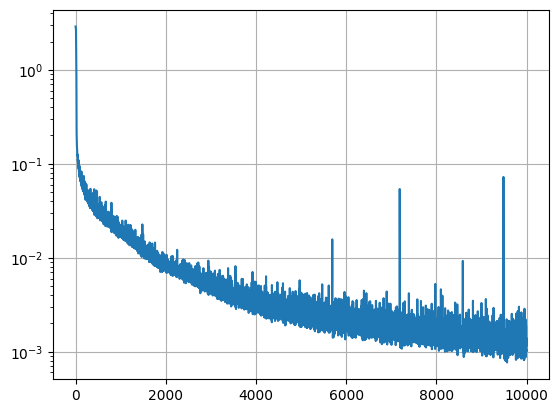

In [ ]:
plt.semilogy(loss)
plt.grid()

In [ ]:
# Create the model
deeponet_soft = DeepONet(t0, tfinal, layers=6, units=40, particles=particles)

# Initialize the model parameters
params_soft = deeponet_soft.init(jax.random.PRNGKey(0), jnp.ones((10,)), jnp.ones((10,2*particles)))

In [ ]:
@jax.jit
def train_step(params, pdes, z):
  t = pdes[:,0]

  # Helper functions
  def a_model(t, z, component, params):
    return deeponet.apply(params, t, z)[0][component][0]
  def b_model(t, z, component, params):
    return deeponet.apply(params, t, z)[1][component][0]
  def a(t, z, component, params):
    return jax.vmap(a_model, [0, 0, None, None])(t, z, component, params)
  def b(t, z, component, params):
    return jax.vmap(b_model, [0, 0, None, None])(t, z, component, params)
  def a_t(t, z, component, params):
    return jax.vmap(jax.grad(a_model, 0), [0, 0, None, None])(t, z, component, params)
  def b_t(t, z, component, params):
    return jax.vmap(jax.grad(b_model, 0), [0, 0, None, None])(t, z, component, params)

  # Soft-constrained DeepONet loss
  def loss(params, t, z):
    eqna, eqnb = [], []
    for k in range(particles):
      if k == 0:
        eqna.append(a_t(t, z, k, params) - 2*(b(t, z, k, params)**2 - b(t, z, particles-1, params)**2))
        eqnb.append(b_t(t, z, k, params) - b(t, z, k, params)*(a(t, z, k+1, params)-a(t, z, k, params)))
      elif k == particles-1:
        eqna.append(a_t(t, z, k, params) - 2*(b(t, z, k, params)**2 - b(t, z, k-1, params)**2))
        eqnb.append(b_t(t, z, k, params) - b(t, z, k, params)*(a(t, z, 0, params)-a(t, z, k, params)))
      else:
        eqna.append(a_t(t, z, k, params) - 2*(b(t, z, k, params)**2 - b(t, z, k-1, params)**2))
        eqnb.append(b_t(t, z, k, params) - b(t, z, k, params)*(a(t, z, k+1, params)-a(t, z, k, params)))

    eqna = jnp.array(eqna)
    eqnb = jnp.array(eqnb)
    physics_loss = jnp.mean(jnp.sum(eqna**2) + jnp.sum(eqnb**2))

    # Hamiltonian loss
    H = jnp.sum(jnp.array([2*a(t, z, j, params)**2+4*b(t, z, j, params)**2 for j in range(particles)]), axis=0)
    H0 = jnp.sum(jnp.array([2*a(0*t, z, j, params)**2+4*b(0*t, z, j, params)**2 for j in range(particles)]), axis=0)
    H_loss = jnp.mean((H-H0)**2)

    return physics_loss + H_loss

  return jax.value_and_grad(loss)(params, t, z)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [ ]:
def train_network(params, des, zsensor, epochs=100):

  # Number of ICs and total number of DE collocation points
  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  lr = 1e-3
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensors)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.zeros(epochs)

  for i in range(epochs):

    for (des_batch, z_batch) in ds:

      loss, grads = train_step(params, des_batch.numpy(), z_batch.numpy())
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    if i % 100 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [20]:
params_soft, loss_soft = train_network(params_soft, de_points, zsensors, epochs)

Loss in epoch 0: 2.89349924551069
Loss in epoch 100: 0.06353625386051079
Loss in epoch 200: 0.03918208986359017
Loss in epoch 300: 0.027809191590568497
Loss in epoch 400: 0.022323794071609098
Loss in epoch 500: 0.020572110835470364
Loss in epoch 600: 0.019293166033095943
Loss in epoch 700: 0.0169900988370803
Loss in epoch 800: 0.015849030891315948
Loss in epoch 900: 0.01692397161367366
Loss in epoch 1000: 0.012956776369114525
Loss in epoch 1100: 0.011646296642754682
Loss in epoch 1200: 0.011793277239467902
Loss in epoch 1300: 0.010643432298512306
Loss in epoch 1400: 0.008160284465220154
Loss in epoch 1500: 0.011738722361393965
Loss in epoch 1600: 0.008115750705960462
Loss in epoch 1700: 0.006866828808232158
Loss in epoch 1800: 0.00757359124228634
Loss in epoch 1900: 0.007331184909779879
Loss in epoch 2000: 0.006832302278205176
Loss in epoch 2100: 0.00541608474065424
Loss in epoch 2200: 0.005256360317458964
Loss in epoch 2300: 0.00446921456665917
Loss in epoch 2400: 0.005014619492171443

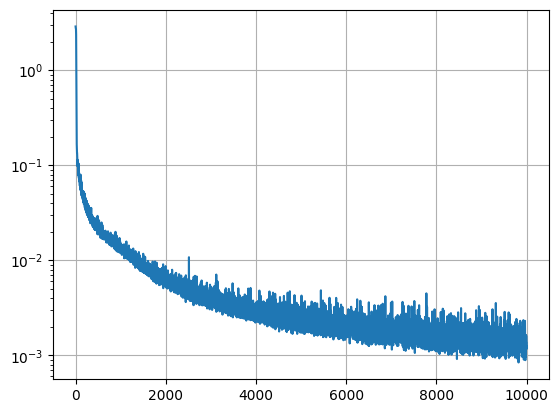

In [21]:
plt.semilogy(loss_soft)
plt.grid()

### Test the model

In [22]:
# Grid where to evaluate the model
n = 100
t = np.linspace(t0, tfinal, n)

# Sample a new IC
init_data = np.random.uniform(-0.5, 0.5, size=(2*particles,))
z = np.repeat(np.expand_dims(init_data, axis=0), len(t), axis=0)

In [23]:
# Model prediction
a, b = deeponet.apply(params, t, z)
a = a.T
b = b.T

# Model prediction
asoft, bsoft = deeponet_soft.apply(params_soft, t, z)
asoft = asoft.T
bsoft = bsoft.T

In [24]:
def TodalLattice(t, w):
  a, b = w[:particles], w[particles:]

  dadt = np.zeros(particles)
  dbdt = np.zeros(particles)

  for k in range(particles):
    if k == 0:
      dadt[k] = 2*(b[k]**2-b[particles-1]**2)
      dbdt[k] = b[k]*(a[k+1]-a[k])
    elif k == particles-1:
      dadt[k] = 2*(b[k]**2-b[k-1]**2)
      dbdt[k] = b[k]*(a[0]-a[k])
    else:
      dadt[k] = 2*(b[k]**2-b[k-1]**2)
      dbdt[k] = b[k]*(a[k+1]-a[k])

  return np.concatenate((dadt, dbdt))

sol_rk = solve_ivp(TodalLattice, [0, tfinal], init_data, t_eval=t).y.T
ark, brk = sol_rk[:,:particles], sol_rk[:,particles:]

In [25]:
# Helper function for the implicit midpoint integrator
def implicitMidpoint(zn, z, dt):
  a, b = z[:particles], z[particles:]
  an, bn = zn[:particles], zn[particles:]

  am = (a + an)/2
  bm = (b + bn)/2

  Fa = np.zeros(particles)
  Fb = np.zeros(particles)

  for k in range(particles):
    if k == 0:
      Fa[k] = (an[k]-a[k])/dt - 2*(bm[k]**2-bm[particles-1]**2)
      Fb[k] = (bn[k]-b[k])/dt - bm[k]*(am[k+1]-am[k])
    elif k == particles-1:
      Fa[k] = (an[k]-a[k])/dt - 2*(bm[k]**2-bm[k-1]**2)
      Fb[k] = (bn[k]-b[k])/dt - bm[k]*(am[0]-am[k])
    else:
      Fa[k] = (an[k]-a[k])/dt - 2*(bm[k]**2-bm[k-1]**2)
      Fb[k] = (bn[k]-b[k])/dt - bm[k]*(am[k+1]-am[k])

  return np.concatenate((Fa, Fb))

# Implicit midpoint integration
def implicit_midpoint(t, z):

  # Total number of integration steps
  steps = len(t)

  dt = t[1] - t[0]

  sol = np.zeros((steps, 2*particles))
  sol[0] = z

  for i in range(1, steps):

    # Midpoint step (Use RK45 as initial guess)
    zg = solve_ivp(TodalLattice, [0, dt], z, t_eval=[dt]).y.T[0]
    zn = fsolve(implicitMidpoint, zg, args=(z, dt), xtol=1e-14)

    # Move solutions
    z = zn

    # Store solution
    sol[i] = z

  return sol

sol_midpoint = implicit_midpoint(t, init_data)
amid, bmid = sol_midpoint[:,:particles], sol_midpoint[:,particles:]

/usr/local/lib/python3.10/dist-packages/scipy/optimize/_minpack_py.py:177: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


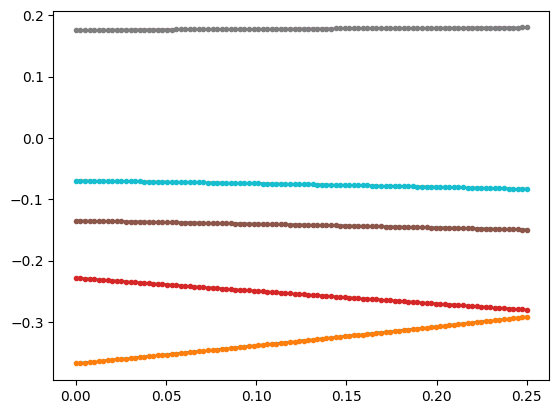

In [26]:
for i in range(particles):
  plt.plot(t, a[:,i])
  plt.plot(t, asoft[:,i],'-.')
  plt.plot(t, ark[:,i],'--')
  plt.plot(t, amid[:,i],'.')

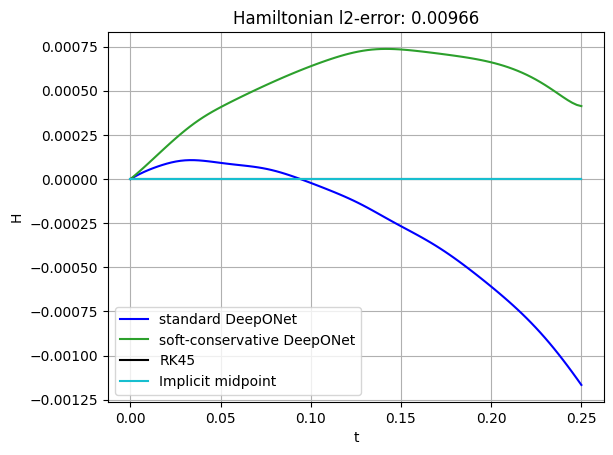

In [27]:
H = np.sum(2*a**2+4*b**2, axis=1)
Hs = np.sum(2*asoft**2+4*bsoft**2, axis=1)
Hrk = np.sum(2*ark**2+4*brk**2, axis=1)
Hmid = np.sum(2*amid**2+4*bmid**2, axis=1)

plt.plot(t, (H-H[0])/H[0],'b')
plt.plot(t, (Hs-Hs[0])/Hs[0],'tab:green')
plt.plot(t, (Hrk-Hrk[0])/Hrk[0],'k')
plt.plot(t, (Hmid-Hmid[0])/Hmid[0],'tab:cyan')

plt.legend(['standard DeepONet', 'soft-conservative DeepONet', 'RK45', 'Implicit midpoint'])
plt.grid()
plt.xlabel('t')
plt.ylabel('H')
plt.title(f'Hamiltonian l2-error: {np.linalg.norm((H-H[0])):2.5f}')
plt.savefig('Hamiltonian1D.png')

In [28]:
def HTrue(w):
  a, b = w[:,:particles], w[:,particles:]
  return jnp.sum(2*a**2 + 4*b**2, axis=1)

g = lambda w, w0: jnp.expand_dims(HTrue(w) - HTrue(w0), axis=1)

def gp(w):
  a, b = w[:,:particles], w[:,particles:]

  grada = [4*a[:,i] for i in range(particles)]
  gradb = [8*b[:,i] for i in range(particles)]
  grad = grada + gradb

  return jnp.column_stack(grad)

gpgptinv = lambda w: jnp.repeat(jnp.expand_dims(1.0/(jnp.sum(gp(w)**2, axis=1)), axis=1), w.shape[1], axis=1)
dlambda = lambda w, w0, l: -1.0*gpgptinv(w)*g(w + l*gp(w), w0)

In [29]:
class ProjectionLayer(nn.Module):

  @nn.compact
  def __call__(self, inputs):
    z, z0, iterations, avg = inputs
    l = jnp.zeros(z.shape)
    lold = l
    for i in range(iterations):
      if i == iterations-1:
        lold = l
      lupdate = dlambda(z, z0, l)
      l += lupdate
    zc = z + gp(z)*l
    zold = z + gp(z)*lold
    return zc*avg + zold*(1.0-avg)

In [30]:
class cDeepONet(nn.Module):

  t0: float
  tfinal: float
  layers: int
  units: int
  particles: int

  @nn.compact
  def __call__(self, t, z0, iterations, avg):

    # # Add the batch dimension
    if z0.ndim == 1:
      z0 = jnp.reshape(z0, (1,-1))

    # Add the batch dimension
    t = jnp.reshape(t, (-1,1))

    b = Normalize(self.t0, self.tfinal)(t)

    trunk_net_q = MLP(self.layers, self.units, self.particles)(b)
    branch_net_q = MLP(self.layers, self.units, self.particles)(z0)

    trunk_net_p = MLP(self.layers, self.units, self.particles)(b)
    branch_net_p = MLP(self.layers, self.units, self.particles)(z0)

    outq, outp = [], []

    # Split into trunk/branch for q and p
    for i in range(self.particles):
      trunk_q = trunk_net_q[:,i*self.units:(i+1)*self.units]
      branch_q = branch_net_q[:,i*self.units:(i+1)*self.units]
      combined_q = CombineBranches()(trunk_q, branch_q)
      constrained_q = HardConstraint(self.t0, self.tfinal, z0[:,i:i+1])([t, combined_q])

      trunk_p = trunk_net_p[:,i*self.units:(i+1)*self.units]
      branch_p = branch_net_p[:,i*self.units:(i+1)*self.units]
      combined_p = CombineBranches()(trunk_p, branch_p)
      constrained_p = HardConstraint(self.t0, self.tfinal,
                                     z0[:,self.particles+i:self.particles+i+1])([t, combined_p])

      outq.append(jnp.reshape(constrained_q, (-1,)))
      outp.append(jnp.reshape(constrained_p, (-1,)))

    outq = jnp.array(outq)
    outp = jnp.array(outp)

    z = jnp.column_stack([jnp.reshape(outq, (1,-1)),
                          jnp.reshape(outp, (1,-1))])

    # # CL projection layer
    z = ProjectionLayer()([z, z0, iterations, avg])

    outq = z[:,:particles].T
    outp = z[:,particles:].T

    return outq, outp

In [31]:
# Create the model
cdeeponet = cDeepONet(t0, tfinal, layers=6, units=40, particles=particles)

# Initialize the model parameters
cparams = cdeeponet.init(jax.random.PRNGKey(0), jnp.ones((1,)), jnp.ones((1,2*particles)),
                         1, 1.0)

In [32]:
# Helper functions
@partial(jax.jit, static_argnums=(2,3,))
def ac_model(t, z, component, iter, avg, params):
  return cdeeponet.apply(params, t, z, iter, avg)[0][component][0]

@partial(jax.jit, static_argnums=(2,3,))
def bc_model(t, z, component, iter, avg, params):
  return cdeeponet.apply(params, t, z, iter, avg)[1][component][0]

@partial(jax.jit, static_argnums=(2,3,))
def a(t, z, component, iter, avg, params):
  return jax.vmap(ac_model, [0, 0, None, None, None, None])(t, z, component, iter, avg, params)

@partial(jax.jit, static_argnums=(2,3,))
def b(t, z, component, iter, avg, params):
  return jax.vmap(bc_model, [0, 0, None, None, None, None])(t, z, component, iter, avg, params)

@partial(jax.jit, static_argnums=(2,3,))
def a_t(t, z, component, iter, avg, params):
  return jax.vmap(jax.grad(ac_model, 0), [0, 0, None, None, None, None])(t, z, component, iter, avg, params)

@partial(jax.jit, static_argnums=(2,3,))
def b_t(t, z, component, iter, avg, params):
  return jax.vmap(jax.grad(bc_model, 0), [0, 0, None, None, None, None])(t, z, component, iter, avg, params)

@partial(jax.jit, static_argnums=(3,))
def loss(params, t, z, iter, avg):

  eqna, eqnb = [], []
  for k in range(particles):
    if k == 0:
      eqna.append(a_t(t, z, k, iter, avg, params) - 2*(b(t, z, k, iter, avg, params)**2 - b(t, z, particles-1, iter, avg, params)**2))
      eqnb.append(b_t(t, z, k, iter, avg, params) - b(t, z, k, iter, avg, params)*(a(t, z, k+1, iter, avg, params)-a(t, z, k, iter, avg, params)))
    elif k == particles-1:
      eqna.append(a_t(t, z, k, iter, avg, params) - 2*(b(t, z, k, iter, avg, params)**2 - b(t, z, k-1, iter, avg, params)**2))
      eqnb.append(b_t(t, z, k, iter, avg, params) - b(t, z, k, iter, avg, params)*(a(t, z, 0, iter, avg, params)-a(t, z, k, iter, avg, params)))
    else:
      eqna.append(a_t(t, z, k, iter, avg, params) - 2*(b(t, z, k, iter, avg, params)**2 - b(t, z, k-1, iter, avg, params)**2))
      eqnb.append(b_t(t, z, k, iter, avg, params) - b(t, z, k, iter, avg, params)*(a(t, z, k+1, iter, avg, params)-a(t, z, k, iter, avg, params)))

  eqna = jnp.array(eqna)
  eqnb = jnp.array(eqnb)

  return jnp.mean(jnp.sum(eqna**2) + jnp.sum(eqnb**2))

@partial(jax.jit, static_argnums=(3,))
def train_step(params, pdes, z, iter, avg):
  t = pdes[:,0]
  return jax.value_and_grad(loss)(params, t, z, iter, avg)

@partial(jax.jit, static_argnums=(3,))
def optimize(grads, opt_state, params, optimizer_update):
  updates, opt_state = optimizer_update(grads, opt_state, params)
  params = optax.apply_updates(params, updates)
  return params, opt_state

In [33]:
def stepFunction(x, epochs, n):
  iteration = 2*np.floor(x*n/epochs).astype(np.int64)
  return iteration

In [34]:
def train_network(params, des, zsensor, epochs=100, maxProjection=10):

  # Number of ICs and total number of DE collocation points
  N = de_points.shape[0]

  nr_batches = 10
  batch_size = len(des)//nr_batches

  lr = 1e-3
  optimizer = optax.adam(lr)
  opt_state = optimizer.init(params)

  ds_z = tf.data.Dataset.from_tensor_slices(zsensors)
  ds_de = tf.data.Dataset.from_tensor_slices(des)

  ds = tf.data.Dataset.zip((ds_de, ds_z))
  ds = ds.shuffle(N).batch(batch_size)

  epoch_loss = np.ones(epochs)

  for i in range(epochs):

    iter = stepFunction(i, epochs, maxProjection)
    avg = (i+1)/epochs

    for (des_batch, z_batch) in ds:

      loss, grads = train_step(params, des_batch.numpy(), z_batch.numpy(), iter, avg)
      params, opt_state = optimize(grads, opt_state, params, optimizer.update)

      epoch_loss[i] += loss

    epoch_loss[i] /= batch_size

    # Weird way to resolve JAX incorrect computation of the mean loss
    epoch_loss[i] -= nr_batches/N

    if i % 10 == 0:
      print(f'Loss in epoch {i}: {epoch_loss[i]}')

  return params, epoch_loss

In [35]:
# Copy the parameters from the trained non-conservative model
cparams = copy.deepcopy(params)

epochs = 0
curr_projection = 1
cparams, loss1 = train_network(cparams, de_points, zsensors, epochs, curr_projection)

epochs = 0
curr_projection = 2
cparams, loss2 = train_network(cparams, de_points, zsensors, epochs, curr_projection)

loss = np.concatenate((loss1, loss2))

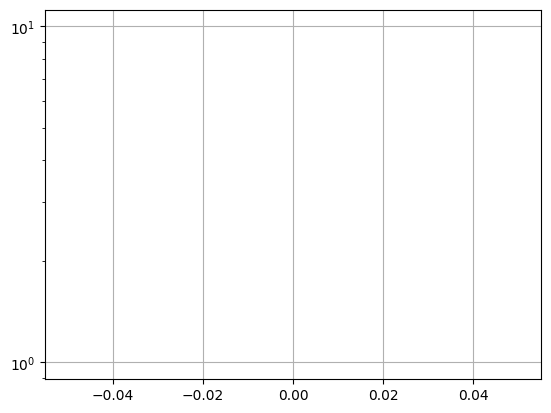

In [36]:
plt.semilogy(loss)
plt.grid()

In [37]:
iters = 20
avg = 1.0

In [ ]:
# Model prediction
ac = []
bc = []

for i in range(particles):
  ac.append(jax.vmap(ac_model, [0, 0, None, None, None, None])(t, z, i, iters, avg, params))
  bc.append(jax.vmap(bc_model, [0, 0, None, None, None, None])(t, z, i, iters, avg, params))

ac = jnp.array(ac).T
bc = jnp.array(bc).T

In [ ]:
# for i in range(particles):
#   plt.plot(t, a[:,i])
#   plt.plot(t, asoft[:,i],'-.')
#   plt.plot(t, ac[:,i],'--')
#   plt.plot(t, ark[:,i],'.')

# plt.legend(['DeepONet','soft-constrained DeepONet',
#             'exactly conservative DeepONet', 'RK45'])
# plt.grid()
# plt.xlabel('t')
# plt.ylabel('a')
# plt.title('Solution time series')

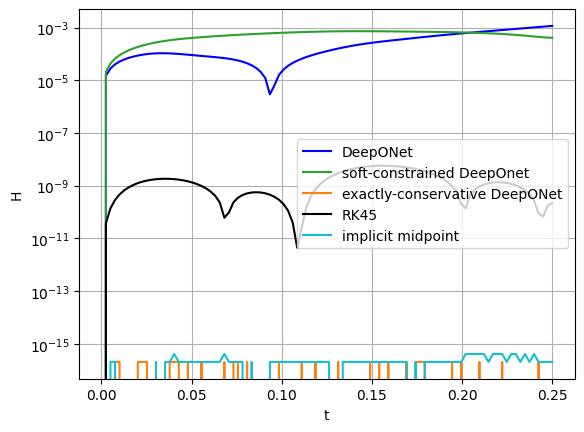

In [ ]:
Hc = np.sum(2*ac**2+4*bc**2, axis=1)

plt.semilogy(t, np.abs(H-H[0])/H[0],'b')
plt.semilogy(t, np.abs(Hs-Hs[0])/Hs[0],'tab:green')
plt.semilogy(t, np.abs(Hc-Hc[0])/Hc[0],'tab:orange')
plt.semilogy(t, np.abs(Hrk-Hrk[0])/Hrk[0],'k')
plt.semilogy(t, np.abs(Hmid-Hmid[0])/Hmid[0],'tab:cyan')

plt.legend(['DeepONet', 'soft-constrained DeepOnet', 'exactly-conservative DeepONet',
            'RK45', 'implicit midpoint'])
plt.grid()
plt.xlabel('t')
plt.ylabel('H')
plt.savefig('Hamiltonian1D.png')

In [ ]:
print(f'Hamiltonian Error: {np.linalg.norm(Hc-Hc[0])}')

Hamiltonian Error: 2.432376777795247e-15


### Time stepping

In [ ]:
# Sample a new IC
init_data = np.random.uniform(-0.5, 0.5, size=(2*particles,))

In [ ]:
steps = 100
tfinalsteps = tfinal*steps
tt = np.linspace(0, tfinalsteps, (n-1)*steps)

In [ ]:
# Non-conservative method
zinit = init_data

aall = []
ball = []

for i in range(steps):
  zinit = np.repeat(np.expand_dims(zinit, axis=0), len(t), axis=0)
  a, b = deeponet.apply(params, t, zinit)
  a = a.T
  b = b.T

  zinit = np.concatenate([a[-1,:], b[-1,:]])
  aall.append(a[:-1,:])
  ball.append(b[:-1,:])

aall = np.concatenate(aall, axis=0)
ball = np.concatenate(ball, axis=0)

In [ ]:
# Soft-conservative method
zinit = init_data

asall = []
bsall = []

for i in range(steps):
  zinit = np.repeat(np.expand_dims(zinit, axis=0), len(t), axis=0)
  asoft, bsoft = deeponet_soft.apply(params_soft, t, zinit)
  asoft = asoft.T
  bsoft = bsoft.T

  zinit = np.concatenate([asoft[-1,:], bsoft[-1,:]])
  asall.append(asoft[:-1,:])
  bsall.append(bsoft[:-1,:])

asall = np.concatenate(asall, axis=0)
bsall = np.concatenate(bsall, axis=0)

In [ ]:
# Exactly conservative method
zinit = init_data

acall = []
bcall = []

for i in range(steps):
  zinit = np.repeat(np.expand_dims(zinit, axis=0), len(t), axis=0)

  a = []
  b = []
  for i in range(particles):
    a.append(jax.vmap(ac_model, [0, 0, None, None, None, None])(t, zinit, i, iters, avg, cparams))
    b.append(jax.vmap(bc_model, [0, 0, None, None, None, None])(t, zinit, i, iters, avg, cparams))

  a = jnp.array(a).T
  b = jnp.array(b).T

  zinit = np.concatenate([a[-1,:], b[-1,:]])
  acall.append(a[:-1,:])
  bcall.append(b[:-1,:])

acall = np.concatenate(acall, axis=0)
bcall = np.concatenate(bcall, axis=0)

In [ ]:
# RK reference solution
zrkall = solve_ivp(TodalLattice, [0, tfinalsteps], init_data, t_eval=tt, rtol=1e-9).y.T
arkall = zrkall[:,:particles]
brkall = zrkall[:,particles:]

In [ ]:
# Implicit midpoint solution
zmidpoint = implicit_midpoint(tt, init_data)
amidall = zmidpoint[:,:particles]
bmidall = zmidpoint[:,particles:]

/usr/local/lib/python3.10/dist-packages/scipy/optimize/_minpack_py.py:177: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  warnings.warn(msg, RuntimeWarning)


In [ ]:
# Implicit midpoint reference solution
fac = 10
tTrue = np.linspace(0, tfinalsteps, fac*(n-1)*steps)
zTrue = implicit_midpoint(tTrue, init_data)[::fac]
aTrue, bTrue = zTrue[:,:particles], zTrue[:,particles:]

In [ ]:
for i in range(particles):
  plt.plot(tt, aall[:,i],'b')
  plt.plot(tt, asall[:,i],'tab:green')
  plt.plot(tt, acall[:,i], 'tab:orange')
  plt.plot(tt, arkall[:,i], 'k')
  plt.plot(tt, amidall[:,i], 'tab:cyan')

plt.legend(['DeepONet', 'soft-conservative DeepONet', 'exactly conservative DeepONet',
            'RK45', 'implicit midpoint'])
plt.grid()
plt.xlabel('$t$')
plt.ylabel('$a$')
plt.savefig('SolutionTodaLatticeA.png')

In [ ]:
for i in range(particles):
  plt.plot(tt, ball[:,i],'b')
  plt.plot(tt, bsall[:,i],'tab:green')
  plt.plot(tt, bcall[:,i], 'tab:orange')
  plt.plot(tt, brkall[:,i], 'k')
  plt.plot(tt, bmidall[:,i], 'tab:cyan')

plt.legend(['DeepONet', 'soft-conservative DeepONet', 'exactly conservative DeepONet',
            'RK45', 'implicit midpoint'])
plt.grid()
plt.xlabel('$t$')
plt.ylabel('$b$')
plt.savefig('SolutionTodaLatticeB.png')

In [ ]:
H = np.sum(2*aall**2+4*ball**2, axis=1)
Hs = np.sum(2*asall**2+4*bsall**2, axis=1)
Hc = np.sum(2*acall**2+4*bcall**2, axis=1)
Hrk = np.sum(2*arkall**2+4*brkall**2, axis=1)
Hmid = np.sum(2*amidall**2+4*bmidall**2, axis=1)

plt.semilogy(tt, np.abs(H-H[0])/H[0],'b')
plt.semilogy(tt, np.abs((Hs-Hs[0])/Hs[0]),'tab:green')
plt.semilogy(tt, np.abs((Hc-Hc[0])/Hc[0]),'tab:orange')
plt.semilogy(tt, np.abs((Hrk-Hrk[0])/Hrk[0]),'k')
plt.semilogy(tt, np.abs((Hmid-Hmid[0])/Hmid[0]),'tab:cyan')

plt.legend(['standard DeepONet', 'soft-conservative DeepONet',
            'exactly conservative DeepONet', 'RK45', 'implicit midpoint'])

plt.grid()
plt.xlabel('t')
plt.ylabel('$|(H-H_0)/H_0|$')

plt.savefig('HamiltonianTodaLattice.png')

In [ ]:
fac = 1

coeff = 0

plt.semilogy(tt[::fac], np.abs(aall[:,coeff]-aTrue[:,coeff])[::fac])
plt.semilogy(tt[::fac], np.abs(asall[:,coeff]-aTrue[:,coeff])[::fac],'tab:green')
plt.semilogy(tt[::fac], np.abs(acall[:,coeff]-aTrue[:,coeff])[::fac],'tab:orange')
plt.semilogy(tt[::fac], np.abs(arkall[:,coeff]-aTrue[:,coeff])[::fac], 'k')
plt.semilogy(tt[::fac], np.abs(amidall[:,coeff]-aTrue[:,coeff])[::fac], 'tab:cyan')

plt.legend(['standard DeepONet', 'soft-conservative DeepONet',
            'exactly conservative DeepONet', 'RK45',
            'implicit midpoint','projection method'])

plt.grid()
plt.xlabel('t')
plt.ylabel('$|a_1-a_1^*|$')
plt.savefig('ErrorTodaLattive.png')